# 2주차 볼린저 평균회귀 — 전략·위험관리 숫자 고정

**목적**: 선택 구간(9/11~10/09) 5분봉으로 전략·위험관리 숫자를 **한 번 계산해 고정**한다. 결과는 `results/params_bollinger.json` 하나로 남기고, `backtest.py`·`trade.py`는 이 파일을 읽는다.

**지키는 것**
1. 숫자를 정하는 **규칙을 먼저** 적고(아래 표), 데이터는 그 규칙에 넣기만 한다.
2. 이 노트북은 **진입 뒤 가격이 어떻게 됐는지(수익률)를 보지 않는다.** 보면 결과가 좋은 숫자를 고르게 된다. 성과는 `backtest.py`에서 본다.
3. 검증 구간(10/12~10/23)은 쓰지 않는다.

## 0. 숫자를 정하는 규칙

| 숫자 | 정하는 규칙 | 근거 |
|---|---|---|
| 봉 | 5분봉 | 2주차 계획 4-2 후보 B |
| 볼린저 기간·폭 | **20봉 · 2σ** (계산하지 않음) | 볼린저밴드 관례값. 최적화하지 않음 |
| 진입("복귀") | 직전 봉 종가 < 하단 **그리고** 이번 봉 종가 ≥ 하단 → 매수. 상단은 대칭으로 매도 | 밴드 밖으로 나갔다가 안으로 돌아온 순간 |
| 진입 가능 시각 | 봉 **마감** 시각 09:00 이상, 15:25 미만 | 모의 운영 09:00~, 15:25 전량 청산 |
| 손절 | 5분봉 ATR(14) 중앙값 × `STOP_K`, 틱 단위 올림 | 평소 5분 흔들림의 몇 배를 넘으면 회귀 가정이 깨졌다고 봄 |
| 익절 | **없음.** 중심선(20봉 평균) 도달 시 청산 | 평균회귀의 목표가 곧 중심선 |
| 일일 손실 한도 | 손절틱 × `LOSS_STOPS` × 1,000원 | "손절 몇 번이면 그날 끝" |
| OI 필터 | 신호 봉 1개(5분) 동안의 미결제약정 변화 | 신호 주기와 같은 길이 |
| 밴드 계산 | `CARRY_OVER=True`면 전일 봉을 이어 씀 | 이어 쓰지 않으면 매일 20봉(100분)이 지나야 첫 신호 가능 |

**팀이 정할 값은 아래 셀의 `[결정 필요]` 3개뿐**이다. 바꾸고 다시 실행하면 그래프와 결과가 따라 바뀐다. 확정되면 `SAVE = True`로 바꿔 한 번 실행한다.

In [1]:
import json
import math
import sys
import urllib.parse
from datetime import datetime
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd()  # week02/
ROOT = HERE.parent
assert (ROOT / "week01" / "first_call.py").exists(), "week02 폴더에서 노트북을 연다"
sys.path.insert(0, str(ROOT / "week01"))
from first_call import BASE_URLS, load_env, post  # noqa: E402

plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False,
                     "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
LONG_C, SHORT_C, MID_C = "#d62728", "#1f77b4", "#555555"  # 매수 빨강 · 매도 파랑 (국내 관례)

SYM = "A066C000"                    # 코스닥150 F 202612
TICK, MULT = 0.1, 10_000            # 호가단위·승수 (product-detail·price 응답, 계획 3절)
TICK_KRW = TICK * MULT              # 1틱 = 1,000원
START, END = "20260911", "20261009"  # 선택 구간 (계획 4-3)

BB_N, BB_K = 20, 2.0
ATR_N = 14
ENTRY_FROM, ENTRY_UNTIL = "09:00", "15:25"  # 봉 마감 시각 기준
COST_TICKS = 2                      # 진입·청산 1틱씩 불리 (계획 4-3). 수수료는 10/26 실측 후 추가

# [결정 필요] 팀이 정하는 값은 이 셋뿐
STOP_K = 2.0        # 손절 = ATR 중앙값 × STOP_K
LOSS_STOPS = 2      # 일일 손실 한도 = 손절 몇 번
CARRY_OVER = True   # 밴드 계산에 전일 봉을 이어 쓸지

SAVE = False        # 위 셋이 확정되면 True 로 바꿔 한 번 실행 → params_bollinger.json

## 1. 데이터 받기

`chart-minute`에 `dcnt=5`(5분 묶음)와 날짜 범위를 주면 5분봉을 바로 받는다. 응답 원본은 `results/`에 저장하고, 파일이 있으면 API를 다시 부르지 않는다.

> 10/24 확인: 날짜 범위를 주면 `req_qty`(300)와 상관없이 구간 전체(1,411봉)가 한 번에 오고, `nxt_key`를 넣어도 같은 데이터가 돌아왔다. 명세의 "기본 300건"과 다른 동작이라 오류 제보 후보다(재현 필요).

In [2]:
RAW = HERE / "results" / f"bars_{SYM}_5m_{START}_{END}.json"

if not RAW.exists():
    env = load_env(ROOT / ".env")
    base = BASE_URLS[env.get("NH_ENV", "paper")]
    token = post(
        f"{base}/auth-service/v1/token",
        urllib.parse.urlencode({
            "grant_type": "client_credentials",
            "appkey": env["NH_DOMESTIC_APP_KEY"],
            "appsecret": env["NH_DOMESTIC_APP_SECRET"],
        }).encode(),
        {"Content-Type": "application/x-www-form-urlencoded"},
    )
    headers = {
        "Authorization": f"{token.get('token_type') or 'Bearer'} {token['access_token']}",
        "Content-Type": "application/json",
    }
    body = {"nght_tp": "1", "sym": SYM, "dcnt": "5", "inq_strt_dt": START, "inq_ed_dt": END, "req_qty": "2000"}
    res = post(f"{base}/trade/v1/domestic/chart-minute", json.dumps(body).encode(), headers)
    rec = {"called_at": datetime.now().isoformat(timespec="seconds"), "server": base,
           "path": "/trade/v1/domestic/chart-minute", "request": body, "response": res}
    RAW.parent.mkdir(exist_ok=True)
    RAW.write_text(json.dumps(rec, ensure_ascii=False, indent=2), encoding="utf-8")
    print("API 호출 → 저장:", RAW.name)
else:
    print("저장본 사용:", RAW.name)

rec = json.loads(RAW.read_text(encoding="utf-8"))
occ = rec["response"]["Occurs1"]
assert int(rec["response"]["nrec"]) == len(occ), "nrec 와 실제 건수가 다르다"

cols = {"open_pric": "open", "high_pric": "high", "low_pric": "low", "close_pric": "close", "opint": "oi"}
bars = (pd.DataFrame(occ)
        .rename(columns=lambda c: c.removeprefix("occurs1_"))
        .assign(t=lambda d: pd.to_datetime(d.ref_dt + d.exch_tm, format="%Y%m%d%H%M%S"))
        .set_index("t").sort_index()[list(cols)].rename(columns=cols).astype(float))
bars["day"] = bars.index.normalize()
bars["auction"] = bars.index.strftime("%H:%M") == "15:45"   # 종료 단일가
bars["close_t"] = bars.index + pd.Timedelta(minutes=5)      # 표기 = 봉 시작 시각 (1-1 점검)
print(f"{len(bars)}봉, {bars.day.nunique()}일, {bars.index[0]} ~ {bars.index[-1]}")
assert bars.index[0] >= pd.Timestamp(START) and bars.index[-1] < pd.Timestamp(END) + pd.Timedelta(days=1)

저장본 사용: bars_A066C000_5m_20260911_20261009.json
1411봉, 17일, 2026-09-11 08:45:00 ~ 2026-10-08 15:45:00


### 1-1. 데이터 점검

- **봉 시각 표기**: 08:45봉에 가격 폭이 있으면(시가≠고가·저가) 08:45~08:50 연속매매를 담은 것이므로, 표기는 **봉 시작 시각**이다. 그래서 봉 마감 시각 = 표기 + 5분으로 둔다.
- **하루 봉 수**: 08:45~15:35 연속매매 82봉 + 15:45 단일가 1봉 = 83봉이 정상이다. 모자란 날이 있으면 빠진 구간이 있다는 뜻이다.

첫날 처음 2봉 / 마지막 3봉
                       open    high     low   close        oi
t                                                            
2026-09-11 08:45:00  1405.0  1408.9  1379.2  1380.2  386873.0
2026-09-11 08:50:00  1380.4  1387.3  1379.3  1386.1  387126.0
2026-09-11 15:25:00  1397.7  1400.8  1397.7  1399.6  394830.0
2026-09-11 15:30:00  1399.5  1400.1  1394.1  1396.1  392271.0
2026-09-11 15:45:00  1395.0  1395.0  1395.0  1395.0  392148.0


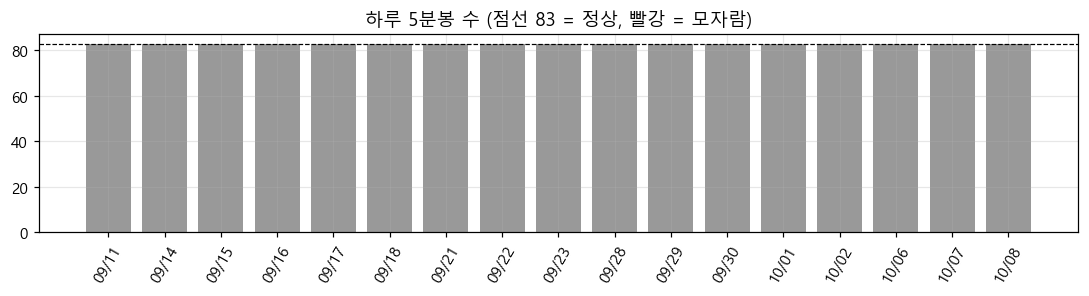

83봉이 아닌 날: 없음


In [3]:
d0 = bars[bars.day == bars.day.iloc[0]]
print("첫날 처음 2봉 / 마지막 3봉")
print(pd.concat([d0.head(2), d0.tail(3)])[["open", "high", "low", "close", "oi"]])

per_day = bars.groupby("day").size()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(per_day.index.strftime("%m/%d"), per_day.values,
       color=np.where(per_day.values == 83, "#999999", LONG_C))
ax.axhline(83, ls="--", c="k", lw=0.8)
ax.set_title("하루 5분봉 수 (점선 83 = 정상, 빨강 = 모자람)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()
print("83봉이 아닌 날:", list(per_day[per_day != 83].index.strftime("%m/%d")) or "없음")

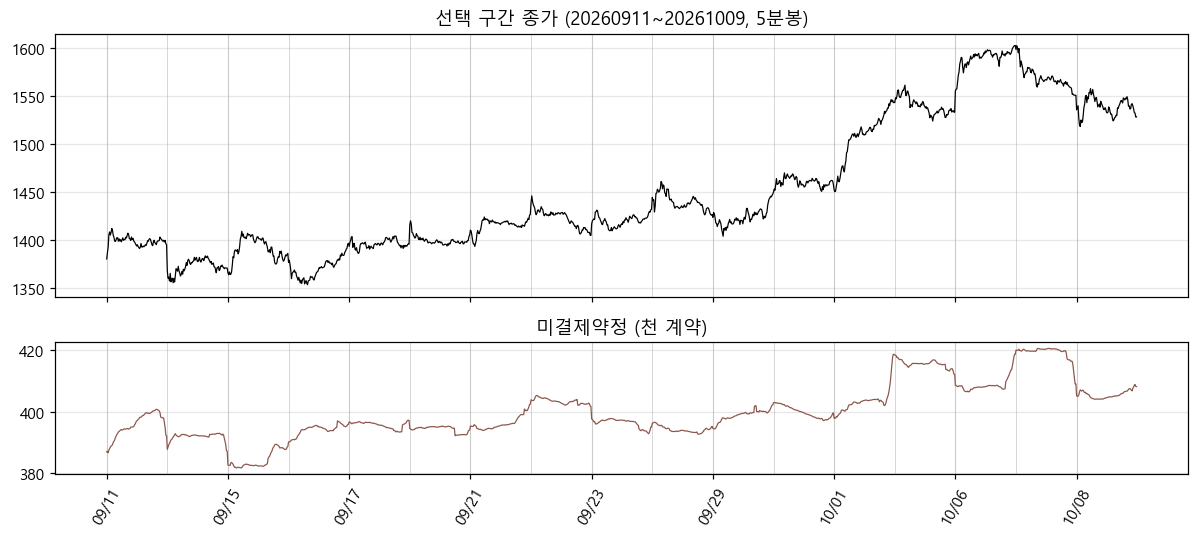

In [4]:
# 밤사이 빈 시간을 지우려고 x축을 봉 순번으로 그린다
x = np.arange(len(bars))
first_idx = np.flatnonzero(bars.day.ne(bars.day.shift()))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(x, bars.close, lw=0.8, c="k")
a1.set_title(f"선택 구간 종가 ({START}~{END}, 5분봉)")
a2.plot(x, bars.oi / 1e3, lw=0.8, c="#8c564b")
a2.set_title("미결제약정 (천 계약)")
for a in (a1, a2):
    for i in first_idx:
        a.axvline(i, c="#cccccc", lw=0.5, zorder=0)
a2.set_xticks(first_idx[::2], bars.day.iloc[first_idx[::2]].dt.strftime("%m/%d"), rotation=60)
plt.tight_layout()
plt.show()

## 2. 신호 — 밴드와 "복귀"

- 중심선 = 최근 20봉 종가 평균, 밴드 = 중심선 ± 2 × 표준편차(모집단 기준, 볼린저 원래 정의)
- **매수**: 직전 봉 종가가 하단 밖(아래), 이번 봉 종가가 하단 안 → 이번 봉 마감에 진입
- **매도**: 직전 봉 종가가 상단 밖(위), 이번 봉 종가가 상단 안

여기서 세는 것은 **신호**다. 실제 거래 수는 보유 중 추가 진입 금지, 일일 한도 때문에 이보다 적다(백테스트에서 확인).

In [5]:
def bollinger(close, day, carry):
    if carry:
        r = close.rolling(BB_N)
        mid, sd = r.mean(), r.std(ddof=0)
    else:
        g = close.groupby(day)
        mid = g.transform(lambda s: s.rolling(BB_N).mean())
        sd = g.transform(lambda s: s.rolling(BB_N).std(ddof=0))
    return mid, mid + BB_K * sd, mid - BB_K * sd


def signals(b, carry):
    mid, up, lo = bollinger(b.close, b.day, carry)
    c, pc = b.close, b.close.shift()
    t = b.close_t.dt.strftime("%H:%M")
    ok = (t >= ENTRY_FROM) & (t < ENTRY_UNTIL) & ~b.auction & b.day.eq(b.day.shift())
    return pd.DataFrame({
        "mid": mid, "up": up, "lo": lo,
        "long": ok & (pc < lo.shift()) & (c >= lo),
        "short": ok & (pc > up.shift()) & (c <= up),
    }, index=b.index)


sig = signals(bars, CARRY_OVER)
sig_alt = signals(bars, not CARRY_OVER)   # 5절에서 비교용
print(f"신호: 매수 {sig.long.sum()} · 매도 {sig.short.sum()}  (CARRY_OVER={CARRY_OVER})")

신호: 매수 37 · 매도 43  (CARRY_OVER=True)


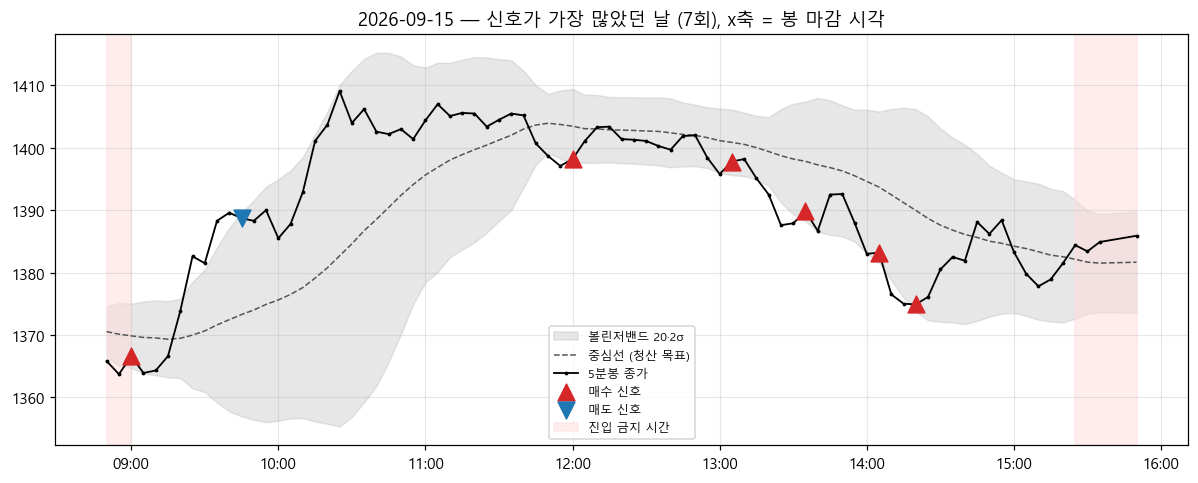

In [6]:
# 신호가 가장 많은 날 하루를 크게
n_by_day = (sig.long | sig.short).groupby(bars.day).sum()
show_day = n_by_day.idxmax()
m = bars.day == show_day
b, s = bars[m], sig[m]
day_str = show_day.strftime("%Y-%m-%d")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(b.close_t, s.lo, s.up, color="#bbbbbb", alpha=0.35, label="볼린저밴드 20·2σ")
ax.plot(b.close_t, s.mid, c=MID_C, lw=1, ls="--", label="중심선 (청산 목표)")
ax.plot(b.close_t, b.close, c="k", lw=1.2, marker=".", ms=3, label="5분봉 종가")
ax.scatter(b.close_t[s.long], b.close[s.long], marker="^", s=120, c=LONG_C, zorder=5, label="매수 신호")
ax.scatter(b.close_t[s.short], b.close[s.short], marker="v", s=120, c=SHORT_C, zorder=5, label="매도 신호")
ax.axvspan(b.close_t.iloc[0], pd.Timestamp(f"{day_str} {ENTRY_FROM}"), color="#ffdddd", alpha=0.5, label="진입 금지 시간")
ax.axvspan(pd.Timestamp(f"{day_str} {ENTRY_UNTIL}"), b.close_t.iloc[-1], color="#ffdddd", alpha=0.5)
ax.set_title(f"{day_str} — 신호가 가장 많았던 날 ({n_by_day.max()}회), x축 = 봉 마감 시각")
ax.legend(loc="best", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

### 2-1. 신호 하나를 확대 — 진입·손절·목표의 위치

손절폭은 3절 규칙으로 여기서 미리 계산해 위치만 보여준다. 이 그림은 **진입 순간의 배치**만 그린 것이고 그 뒤 가격은 일부러 그리지 않았다(수익률을 보지 않는 원칙).

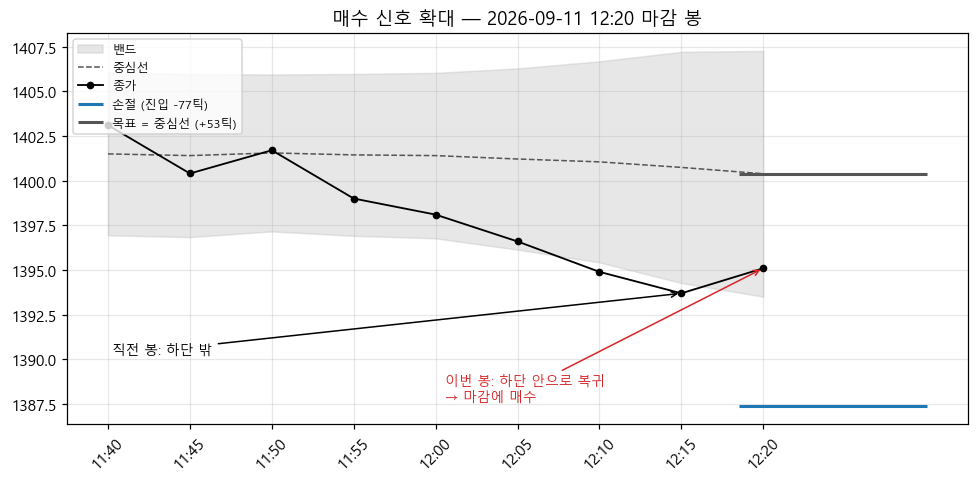

In [7]:
# 3절 계산 (손절폭이 그림에 필요해 먼저 한다)
pc_day = bars.close.shift().where(bars.day.eq(bars.day.shift()))   # 전일 종가와는 비교하지 않음 = 밤사이 갭 제외
tr = pd.concat([bars.high - bars.low, (bars.high - pc_day).abs(), (bars.low - pc_day).abs()], axis=1).max(axis=1)
atr = tr.rolling(ATR_N).mean()   # 전일 봉에서 이어 계산 (갭은 TR 에서 이미 뺐다)
t_close = bars.close_t.dt.strftime("%H:%M")
in_win = (t_close >= ENTRY_FROM) & (t_close < ENTRY_UNTIL) & ~bars.auction
atr_med_ticks = atr[in_win].median() / TICK
STOP_TICKS = math.ceil(STOP_K * atr_med_ticks)

i = np.flatnonzero(sig.long)[0]
b, s = bars.iloc[i - 8:i + 1], sig.iloc[i - 8:i + 1]
entry, target = b.close.iloc[-1], s.mid.iloc[-1]
xs = np.arange(len(b))
j = xs[-1]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(xs, s.lo, s.up, color="#bbbbbb", alpha=0.35, label="밴드")
ax.plot(xs, s.mid, c=MID_C, ls="--", lw=1, label="중심선")
ax.plot(xs, b.close, c="k", marker="o", ms=4, lw=1.2, label="종가")
ax.annotate("직전 봉: 하단 밖", (j - 1, b.close.iloc[-2]), (0.05, 0.18), textcoords="axes fraction",
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate("이번 봉: 하단 안으로 복귀\n→ 마감에 매수", (j, entry), (0.42, 0.06), textcoords="axes fraction",
            arrowprops=dict(arrowstyle="->", color=LONG_C), fontsize=9, color=LONG_C)
ax.hlines(entry - STOP_TICKS * TICK, j - 0.3, j + 2, colors=SHORT_C, lw=2, label=f"손절 (진입 -{STOP_TICKS}틱)")
ax.hlines(target, j - 0.3, j + 2, colors=MID_C, lw=2, label=f"목표 = 중심선 (+{(target - entry) / TICK:.0f}틱)")
ax.set_xticks(xs, b.close_t.dt.strftime("%H:%M"), rotation=45)
ax.set_xlim(-0.5, j + 2.5)
ax.set_title(f"매수 신호 확대 — {bars.index[i]:%Y-%m-%d} {b.close_t.iloc[-1]:%H:%M} 마감 봉")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 3. 손절 — 평소 5분 흔들림(ATR) 기준

- **TR**(True Range) = 그 봉의 고가−저가, 직전 봉 종가와의 거리 중 가장 큰 값. 하루 첫 봉은 **밤사이 갭을 빼려고** 전일 종가와 비교하지 않는다.
- **ATR(14)** = 최근 14봉 TR 평균. 진입 가능 시간대 봉들의 **중앙값**을 "평소 흔들림"으로 본다(평균은 급변동 며칠에 끌려간다).
- 손절 틱 = ⌈ATR 중앙값 × `STOP_K`⌉

ATR(14) 중앙값 38.4틱  →  손절 = ⌈38.4 × 2.0⌉ = 77틱 (77,000원)


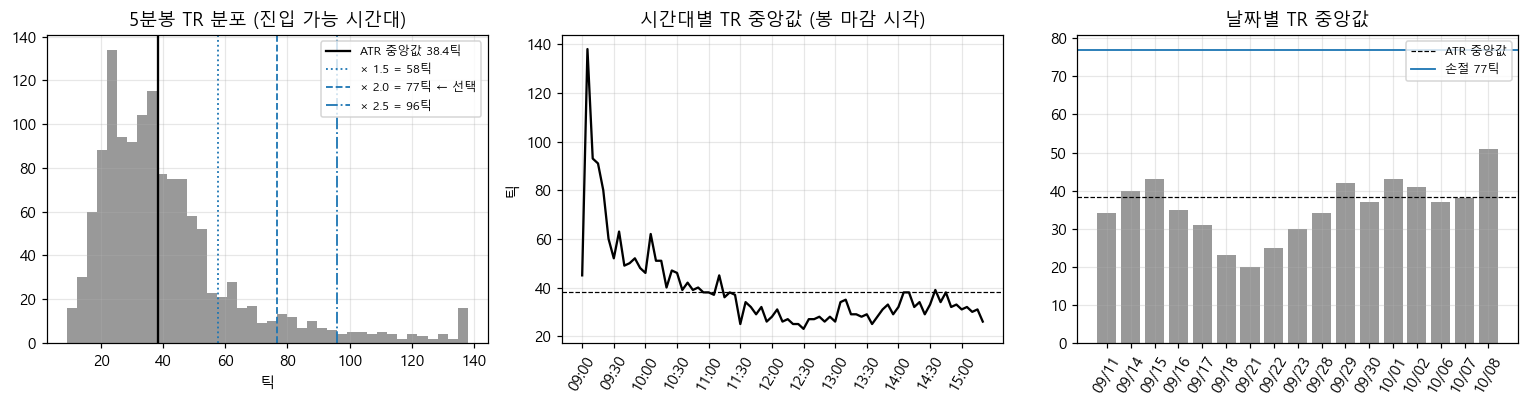

참고: 하루 TR 중앙값 범위 20.0 ~ 51.0틱 — 손절틱을 고정하면 변동성 큰 날엔 좁고 작은 날엔 넓다


In [8]:
tr_ticks = tr[in_win] / TICK
print(f"ATR(14) 중앙값 {atr_med_ticks:.1f}틱  →  손절 = ⌈{atr_med_ticks:.1f} × {STOP_K}⌉ = {STOP_TICKS}틱 ({STOP_TICKS * TICK_KRW:,.0f}원)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

ax = axes[0]
ax.hist(tr_ticks.clip(upper=tr_ticks.quantile(0.99)), bins=40, color="#999999")
ax.axvline(atr_med_ticks, c="k", lw=1.5, label=f"ATR 중앙값 {atr_med_ticks:.1f}틱")
for k, ls in [(1.5, ":"), (2.0, "--"), (2.5, "-.")]:
    ax.axvline(atr_med_ticks * k, c=SHORT_C, ls=ls, lw=1.2,
               label=f"× {k} = {math.ceil(atr_med_ticks * k)}틱" + (" ← 선택" if k == STOP_K else ""))
ax.set_title("5분봉 TR 분포 (진입 가능 시간대)")
ax.set_xlabel("틱")
ax.legend(fontsize=8)

ax = axes[1]
slot = tr_ticks.groupby(bars.close_t[in_win].dt.strftime("%H:%M")).median()
ax.plot(slot.index, slot.values, c="k")
ax.axhline(atr_med_ticks, c="k", ls="--", lw=0.8)
ax.set_xticks(slot.index[::6])
ax.tick_params(axis="x", rotation=60)
ax.set_title("시간대별 TR 중앙값 (봉 마감 시각)")
ax.set_ylabel("틱")

ax = axes[2]
daily = tr_ticks.groupby(bars.day[in_win]).median()
ax.bar(daily.index.strftime("%m/%d"), daily.values, color="#999999")
ax.axhline(atr_med_ticks, c="k", ls="--", lw=0.8, label="ATR 중앙값")
ax.axhline(STOP_TICKS, c=SHORT_C, lw=1.2, label=f"손절 {STOP_TICKS}틱")
ax.tick_params(axis="x", rotation=60)
ax.set_title("날짜별 TR 중앙값")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print(f"참고: 하루 TR 중앙값 범위 {daily.min():.1f} ~ {daily.max():.1f}틱 — 손절틱을 고정하면 변동성 큰 날엔 좁고 작은 날엔 넓다")

## 4. 익절 대신 중심선 — 목표 거리가 비용보다 큰가

신호 순간의 **진입가~중심선 거리**를 본다. 진입 뒤 실제로 거기까지 갔는지는 보지 않는다(백테스트 몫).
- 거리가 비용(왕복 2틱 + 수수료)에 가까우면 이겨도 남는 게 없다.
- 거리 ÷ 손절폭 = 이길 때와 질 때의 크기 비. 이 비가 작을수록 승률이 높아야 본전이다.

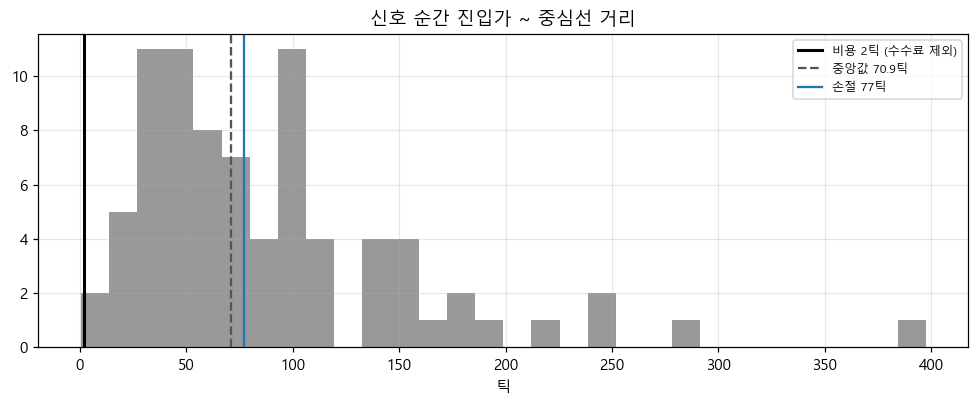

거리 중앙값 70.9틱, 비용 이하 비율 1%
목표:손절 = 70.9 : 77 = 0.92
→ 중앙값 기준 본전 승률 ≈ (77+2) / (77+70.9) = 53%


In [9]:
hit = sig.long | sig.short
dist = ((sig.mid - bars.close).abs() / TICK)[hit]
med_dist = dist.median()
rr = med_dist / STOP_TICKS
# 목표 도달(+거리) 또는 손절(−손절폭) 둘 중 하나로 끝난다고 단순화, 양쪽 다 비용 차감
breakeven = (STOP_TICKS + COST_TICKS) / (STOP_TICKS + med_dist)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(dist, bins=30, color="#999999")
ax.axvline(COST_TICKS, c="k", lw=2, label=f"비용 {COST_TICKS}틱 (수수료 제외)")
ax.axvline(med_dist, c=MID_C, ls="--", lw=1.5, label=f"중앙값 {med_dist:.1f}틱")
ax.axvline(STOP_TICKS, c=SHORT_C, lw=1.5, label=f"손절 {STOP_TICKS}틱")
ax.set_title("신호 순간 진입가 ~ 중심선 거리")
ax.set_xlabel("틱")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"거리 중앙값 {med_dist:.1f}틱, 비용 이하 비율 {(dist <= COST_TICKS).mean():.0%}")
print(f"목표:손절 = {med_dist:.1f} : {STOP_TICKS} = {rr:.2f}")
print(f"→ 중앙값 기준 본전 승률 ≈ ({STOP_TICKS}+{COST_TICKS}) / ({STOP_TICKS}+{med_dist:.1f}) = {breakeven:.0%}")

## 5. 신호 수 — 실전 4일에 거래가 생기나

하루 1회도 안 되면 실전(10/27~10/30)에 거래가 거의 안 생겨 「실행·분석」을 채우기 어렵다. 이 경우 **숫자를 조정하지 말고 후보를 바꾼다.**
오른쪽 그림은 `CARRY_OVER`(전일 봉 이어 쓰기)를 바꾸면 신호가 어느 시간대에서 생기고 사라지는지 보여준다.
9시대 신호가 `CARRY_OVER`에 따라 크게 달라지면, 그 신호는 **밤사이 갭이 전일 밴드를 벗어나서** 생긴 것이다. 3절 시간대별 TR에서 장 초반 변동이 큰 것과 같은 원인이라, 장중 평균회귀와는 성격이 다른 신호다.

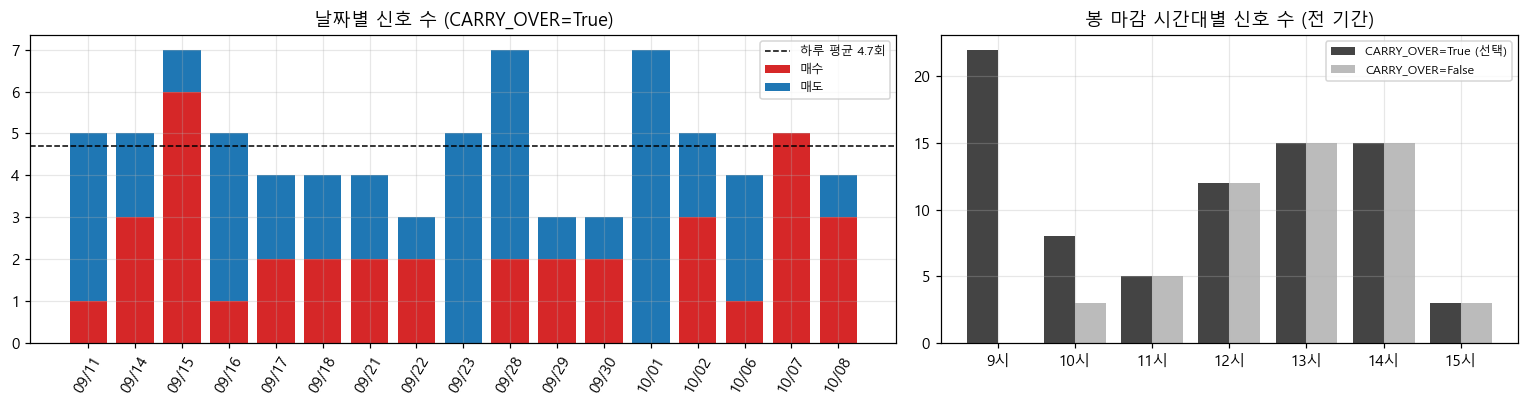

하루 평균 신호 4.7회 (최소 3 · 최대 7), 신호 0회인 날 0일
CARRY_OVER=False 였다면 하루 평균 3.1회


In [10]:
days = bars.day.unique()
per = pd.DataFrame({"매수": sig.long.groupby(bars.day).sum(),
                    "매도": sig.short.groupby(bars.day).sum()}).reindex(days, fill_value=0)
tot = per.sum(axis=1)
spd = tot.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
lbl = per.index.strftime("%m/%d")
ax.bar(lbl, per["매수"], color=LONG_C, label="매수")
ax.bar(lbl, per["매도"], bottom=per["매수"], color=SHORT_C, label="매도")
ax.axhline(spd, c="k", ls="--", lw=1, label=f"하루 평균 {spd:.1f}회")
ax.tick_params(axis="x", rotation=60)
ax.set_title(f"날짜별 신호 수 (CARRY_OVER={CARRY_OVER})")
ax.legend(fontsize=8)

ax = axes[1]
hours = np.arange(9, 16)
def by_hour(s):
    return bars.close_t[s.long | s.short].dt.hour.value_counts().reindex(hours, fill_value=0)
ax.bar(hours - 0.2, by_hour(sig), 0.4, color="#444444", label=f"CARRY_OVER={CARRY_OVER} (선택)")
ax.bar(hours + 0.2, by_hour(sig_alt), 0.4, color="#bbbbbb", label=f"CARRY_OVER={not CARRY_OVER}")
ax.set_xticks(hours, [f"{h}시" for h in hours])
ax.set_title("봉 마감 시간대별 신호 수 (전 기간)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"하루 평균 신호 {spd:.1f}회 (최소 {tot.min()} · 최대 {tot.max()}), 신호 0회인 날 {(tot == 0).sum()}일")
print(f"CARRY_OVER={not CARRY_OVER} 였다면 하루 평균 {(sig_alt.long | sig_alt.short).sum() / len(days):.1f}회")

## 6. OI 필터 — 신호 봉의 미결제약정 변화

신호 봉 1개(5분) 동안 OI가 늘었는지 줄었는지만 센다. 필터를 켜면 신호가 얼마나 줄어드는지 미리 보는 용도다.

해석 [추정]: 평균회귀에서는 밴드 이탈 중 **OI 증가** = 새 돈이 그 방향으로 미는 중 → 회귀가 약할 수 있음, **OI 감소** = 기존 포지션 청산에 의한 일시 이탈 → 회귀 가능성. 추세 전략(A·C)과 방향이 반대다. 어느 쪽이 맞는지는 백테스트에서 필터 없음 / OI 증가만 / OI 감소만을 비교해 본다.

       OI 증가  변화 없음  OI 감소
매도 신호     18      0     25
매수 신호     25      0     12


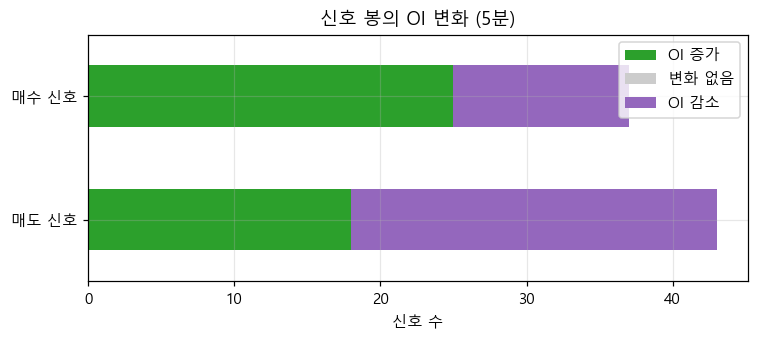

OI 감소만 남기면 하루 평균 2.2회, OI 증가만 남기면 2.5회


In [11]:
doi = bars.oi.diff()[hit]
side = pd.Series(np.where(sig.long[hit], "매수 신호", "매도 신호"), index=doi.index)
oi_dir = np.sign(doi).map({1.0: "OI 증가", 0.0: "변화 없음", -1.0: "OI 감소"})
tab = pd.crosstab(side, oi_dir).reindex(columns=["OI 증가", "변화 없음", "OI 감소"], fill_value=0)
tab.index.name = tab.columns.name = None
print(tab)

fig, ax = plt.subplots(figsize=(7, 3.2))
tab.plot.barh(stacked=True, ax=ax, color=["#2ca02c", "#cccccc", "#9467bd"])
ax.set_title("신호 봉의 OI 변화 (5분)")
ax.set_xlabel("신호 수")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
print(f"OI 감소만 남기면 하루 평균 {tab['OI 감소'].sum() / len(days):.1f}회, OI 증가만 남기면 {tab['OI 증가'].sum() / len(days):.1f}회")

## 7. 일일 손실 한도

In [12]:
DAILY_LOSS_KRW = STOP_TICKS * LOSS_STOPS * TICK_KRW
print(f"일일 손실 한도 = 손절 {STOP_TICKS}틱 × {LOSS_STOPS}회 × {TICK_KRW:,.0f}원 = {DAILY_LOSS_KRW:,.0f}원 (1계약)")
print("닿으면 그날 신규 진입 중지. 보유 포지션은 원래 규칙(손절·중심선·15:25)대로 청산")

일일 손실 한도 = 손절 77틱 × 2회 × 1,000원 = 154,000원 (1계약)
닿으면 그날 신규 진입 중지. 보유 포지션은 원래 규칙(손절·중심선·15:25)대로 청산


## 8. 결과 — 고정값

`SAVE = True`일 때만 `results/params_bollinger.json`을 쓴다. **이미 파일이 있으면 덮어쓰지 않는다.** 백테스트를 본 뒤 숫자를 바꾸고 싶어지면, 파일을 지우기 전에 바꾸는 이유를 README에 먼저 남긴다.

In [13]:
params = {
    "symbol": SYM,
    "bar_minutes": 5,
    "bollinger": {"n": BB_N, "k": BB_K, "std_ddof": 0, "carry_over": CARRY_OVER},
    "entry": "prev_close outside band AND close back inside band, at bar close",
    "entry_window_close_time": [ENTRY_FROM, ENTRY_UNTIL],
    "force_exit_time": ENTRY_UNTIL,
    "exit": "middle band",
    "take_profit_ticks": None,
    "stop_ticks": STOP_TICKS,
    "daily_loss_limit_krw": DAILY_LOSS_KRW,
    "oi_filter_bars": 1,
    "contracts": 1,
    "basis": {
        "source": RAW.relative_to(ROOT).as_posix(),
        "selection_period": [START, END],
        "days": int(len(days)),
        "atr_n": ATR_N,
        "atr_median_ticks": round(atr_med_ticks, 2),
        "stop_k": STOP_K,
        "loss_stops": LOSS_STOPS,
    },
    "checks": {
        "signals_per_day": round(spd, 2),
        "median_dist_to_mid_ticks": round(med_dist, 2),
        "cost_ticks": COST_TICKS,
        "target_to_stop": round(rr, 2),
    },
}

print(pd.Series({
    "볼린저": f"{BB_N}봉 · {BB_K}σ (5분봉, 전일 이어쓰기={CARRY_OVER})",
    "진입": f"밴드 밖 → 안 복귀, 봉 마감 {ENTRY_FROM}~{ENTRY_UNTIL}",
    "청산": f"중심선 · 손절 {STOP_TICKS}틱 · {ENTRY_UNTIL} 전량",
    "일일 손실 한도": f"{DAILY_LOSS_KRW:,.0f}원",
    "점검: 하루 신호": f"{spd:.1f}회",
    "점검: 목표:손절": f"{med_dist:.1f} : {STOP_TICKS} 틱",
}).to_string())

OUT = HERE / "results" / "params_bollinger.json"
if not SAVE:
    print("\nSAVE=False — 저장하지 않음")
elif OUT.exists():
    print(f"\n{OUT.name} 이미 있음 — 덮어쓰지 않는다")
else:
    params["fixed_at"] = datetime.now().isoformat(timespec="seconds")
    OUT.write_text(json.dumps(params, ensure_ascii=False, indent=2), encoding="utf-8")
    print("\n저장:", OUT.relative_to(ROOT).as_posix())

볼린저          20봉 · 2.0σ (5분봉, 전일 이어쓰기=True)
진입            밴드 밖 → 안 복귀, 봉 마감 09:00~15:25
청산                  중심선 · 손절 77틱 · 15:25 전량
일일 손실 한도                           154,000원
점검: 하루 신호                              4.7회
점검: 목표:손절                       70.9 : 77 틱

SAVE=False — 저장하지 않음
